# Solving linear system of equations

Useful libraries for this notebook:

In [1]:
import numpy as np
import numpy.linalg as la
import scipy.linalg as sla
import scipy.sparse as sparse


import matplotlib.pyplot as plt
%matplotlib inline

from PIL import Image

import seaborn as sns
sns.set(font_scale=2)

from time import time


## 1) Transforming images using linear operators:

### Import an image of a Social Security Number

In [2]:
img = Image.open('ssn.png')
xmat = (255 - np.asarray(img).max(axis=2))/255

In [3]:
print(xmat.shape)
print(xmat.min(),xmat.max())


(40, 100)
0.0 1.0


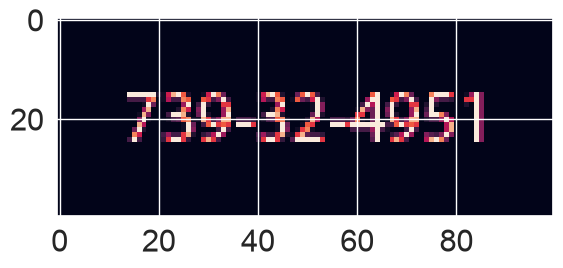

In [4]:
plt.imshow(xmat);

#### "Vectorize" the image, creating the 1d array `x`

In [5]:
x = xmat.flatten()
x.shape

(4000,)

### Construct a "blur" matrix

In [6]:
def blur_operator(m,n,radius):
    imat, jmat = np.meshgrid(np.arange(m), np.arange(n), indexing='ij')
    ivec = np.atleast_2d(imat.flatten())
    jvec = np.atleast_2d(jmat.flatten())
    A = np.fmax(0, 1 - np.sqrt((ivec.T - ivec)**2 + (jvec.T - jvec)**2)/radius)
    A /= A.sum(axis=1)
    return A

In [7]:
A = blur_operator(xmat.shape[0],xmat.shape[1],5)
A.shape

(4000, 4000)

### Compute b = A x

In [8]:
b = A @ x
b.shape

(4000,)

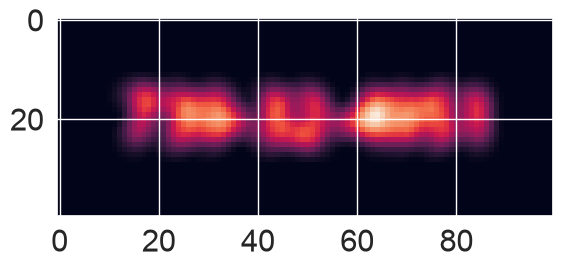

In [9]:
b2D = b.reshape(xmat.shape)
plt.imshow(b2D)

### Assume we have the blurred image (b), solve for the unblurred one (x)

In essence, we want $x = A^{-1} b$. Instead of evaluating the inverse, we can evaluate:

#### a)  `np.linalg.solve`:

In [10]:
x_solve1 = la.solve(A,b)
x_solve1.shape

(4000,)

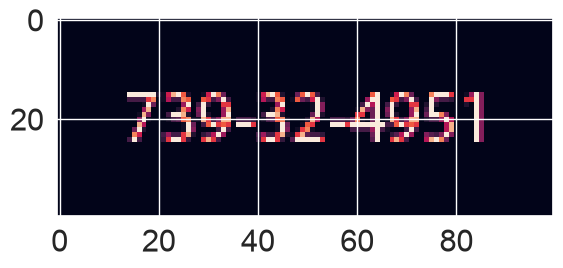

In [11]:
plt.imshow(x_solve1.reshape(xmat.shape))

Voila! We have our recovered original image :-)

We can check the results with inverse (but we will avoid using inverse in this course. More to come on that soon!)

In [12]:
xx = la.inv(A)@b
np.isclose(xx, x_solve1, rtol=1e-05, atol=1e-08, equal_nan=False).sum()

np.int64(4000)

### Now add some noise

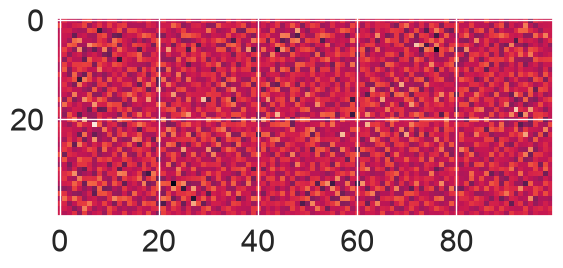

In [13]:
b_noisy = b + 1e-3 * np.random.rand(b.size)

x_noisy = la.solve(A,b_noisy)

plt.imshow(x_noisy.reshape(xmat.shape))


What happened to your solution. We will soon be talking about conditioning of matrices. 

## 2) Solving Triangular Systems

https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve_triangular.html

#### Forward-substitution:

$$
\left[\begin{matrix}L_{11} & 0 & 0 & 0\\ L_{21} & L_{22} & 0 & 0\\L_{31} & L_{32} & L_{33} & 0\\L_{41} & L_{42} & L_{43} & L_{44}\end{matrix}\right] \begin{bmatrix}x_1 \\ x_2 \\ x_3 \\ x_4\end{bmatrix} = \begin{bmatrix}b_1 \\ b_2 \\ b_3 \\ b_4\end{bmatrix}
$$

For example,

$$
\left[\begin{matrix}2 & 0 & 0 & 0\\3 & 2 & 0 & 0\\1 & 2 & 6 & 0\\1 & 3 & 4 & 2\end{matrix}\right] \begin{bmatrix}x_1 \\ x_2 \\ x_3 \\ x_4\end{bmatrix} = \begin{bmatrix}2 \\ 2 \\ 6 \\ 4\end{bmatrix}
$$

The solution for forward substitution is:
$$
x_1 = \frac{b_1}{L_{11}} 
$$
$$
x_i = \frac{b_i - \sum_{j=1}^{i-1} L_{ij} x_j}{L_{ii}}, \quad i = 2, 3, \cdots, n
$$

In [14]:
M1 = np.array([[2,0,0,0],[3,2,0,0],[1,2,6,0],[1,3,4,2]])
b1 = np.array([2,2,6,4])

In [15]:
def my_forward_substitution(M,b):
    n = len(b)
    y = np.zeros(n)
    for i in range(n):
        tmp = b[i]
        for j in range(i):
            tmp -= y[j]*M[i,j]
        y[i]=tmp/M[i,i]
    return y

In [16]:
my_forward_substitution(M1,b1)

array([ 1.  , -0.5 ,  1.  ,  0.25])

In [17]:
sla.solve_triangular(M1, b1, lower=True)

array([ 1.  , -0.5 ,  1.  ,  0.25])

#### Backward-substitution:

$$
\left[\begin{matrix}U_{11} & U_{12} & U_{13} & U_{14}\\0 & U_{21} & U_{22} & U_{23}\\0 & 0 & U_{33} & U_{34}\\0 & 0 & 0 & U_{44}\end{matrix}\right]  \begin{bmatrix}x_1 \\ x_2 \\ x_3 \\ x_4\end{bmatrix} = \begin{bmatrix}b_1 \\ b_2 \\ b_3 \\ b_4\end{bmatrix}
$$

For example,

$$
\left[\begin{matrix}2 & 8 & 4 & 2\\0 & 4 & 4 & 3\\0 & 0 & 6 & 2\\0 & 0 & 0 & 2\end{matrix}\right] \begin{bmatrix}x_1 \\ x_2 \\ x_3 \\ x_4\end{bmatrix} = \begin{bmatrix}2 \\ 4 \\ 4 \\ 1\end{bmatrix}
$$

The solution for forward substitution is:
$$
x_n = \frac{b_n}{L_{nn}} 
$$
$$
x_i = \frac{b_i - \sum_{j=i+1}^{n} U_{ij}x_j}{U_{ii}}, i = n-1, n-2,\cdots, 1
$$

In [18]:
M2 = np.array([[2,8,4,2],[0,4,4,3],[0,0,6,2],[0,0,0,2]])
b2 = np.array([2,4,4,1])

In [19]:
def my_backward_substitution(M,b):
    n = len(b)
    y = np.zeros(n)
    for i in range(n-1, -1, -1):
        tmp = b[i]
        for j in range(i+1, n):
            tmp -= y[j]*M[i,j]
        y[i] = tmp/M[i,i]
    return y

In [20]:
my_backward_substitution(M2,b2)

array([-1.   ,  0.125,  0.5  ,  0.5  ])

In [21]:
sla.solve_triangular(M2, b2)

array([-1.   ,  0.125,  0.5  ,  0.5  ])

## 3) LU Factorization (without pivoting)

### Factorize and solve resulting triangular systems

1) Factorize:

$$A = L U$$
where
$$
L = \begin{bmatrix}
1 & 0 & \cdots & 0\\
L_{21} & 1 & \cdots & 0\\
\vdots & \vdots & \ddots & \vdots\\
L_{n1} & L_{n2} & \cdots & 1
\end{bmatrix} \\
U = \begin{bmatrix}
U_{11} & U_{12} & \cdots & U_{1n}\\
0 & U_{22} & \cdots & U_{2n}\\
\vdots & \vdots & \ddots & \vdots\\
0 & 0 & \cdots & U_{nn}
\end{bmatrix}
$$

to solve $Ax=b$

2) Forward substitution:

$y \leftarrow \text{solve}\,\, L y = b$
    
$$ y_i = b_i - \sum_{j=1}^{i-1} L_{ij} y_j \quad i=1,2,3,...,n$$

Backward substitution:
    
$x \leftarrow \text{solve}\,\, U x = y$

$$ x_i = y_i - \sum_{j=i+1}^{n} U_{ij} x_j \quad i=n, n-1, n-2, ..., 1$$

#### What is happening inside "solve"?



A factorization and substitutions. For example, let's think of LU factorization:

If $Ax = P L U x = b$, then there are two steps:
1. $y \leftarrow \text{solve}\,\, L y = P^Tb$
2. $x \leftarrow \text{solve}\,\, U x = y$

####  LU factorization and triangular substitutions:

In [22]:
import scipy.linalg as sla
P, L, U = sla.lu(A)

P.shape

(4000, 4000)

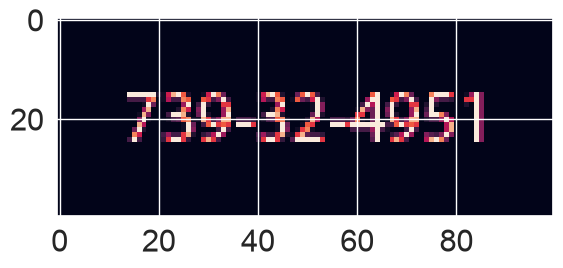

In [23]:
y = sla.solve_triangular(L, P.T@b, lower=True)

x_solve = sla.solve_triangular(U, y)

plt.imshow(x_solve.reshape(xmat.shape))

#### Why not just `np.linalg.solve`?

Suppose you have many social security numbers to un-blur. You should factorize your blur matrix only once and then perform several triangular solves.

Let's time:

1. solve including factorization
2. factorization
3. solve, given a factorization

In [24]:
%timeit sla.solve(A, b)

301 ms ± 2.94 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [25]:
%timeit P, L, U = sla.lu(A)

318 ms ± 1.75 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [26]:
%timeit sla.solve_triangular(U, y)

9.37 ms ± 240 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


### Let's take a look at the matrix format

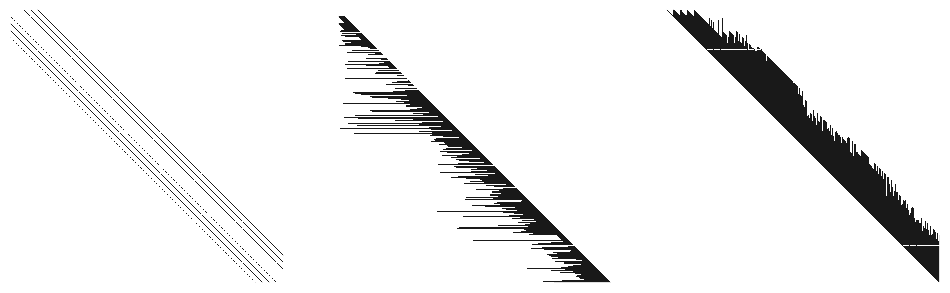

In [27]:
plt.figure(figsize=(12,6))
plt.subplot(131)
plt.spy(A); plt.xticks([]); plt.yticks([]);

plt.subplot(132)
plt.spy(L); plt.xticks([]); plt.yticks([]);

plt.subplot(133)
plt.spy(U); plt.xticks([]); plt.yticks([]);

Note that many entries of the matrices are zeros! We don't need to store all of the zeros. In fact, we can even use solvers that efficiently take into account the format of the matrices.

In [28]:
 A_csr = sparse.csr_matrix(A)

In [29]:
%timeit sparse.linalg.spsolve(A_csr,b)

197 ms ± 2.48 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


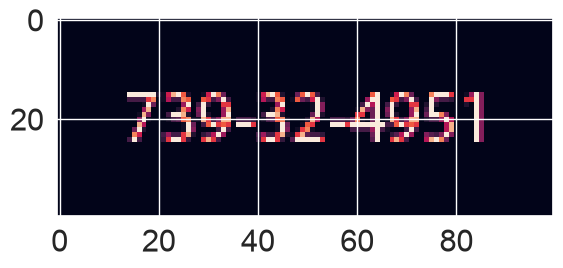

In [30]:
x_solve_3 = sparse.linalg.spsolve(A_csr,b)
plt.imshow(x_solve_3.reshape(xmat.shape))

This is just a teaser :-) We will talk more later about sparse systems.

## 4) Example:  Topology design optimization

![](myfigure.png)

When performing optimization of structural problem, for example to obtain the bridge design above, you may want to use a numerical method called Finite Element Method (you will learn this in a future MP). The optimization will consist of a series of `solve` of the form:
$$ {\bf K} {\bf u} = {\bf F} $$

Here will load the matrix $ {\bf K}$ from a file. The matrix is given in Compressed Sparse Column (CSC) format.

In [31]:
K = sparse.load_npz('yourmatrix.npz')
K

<Compressed Sparse Column sparse matrix of dtype 'float64'
	with 105912 stored elements and shape (6600, 6600)>

We can `spy` the distribution of the non-zero entries of the matrix:

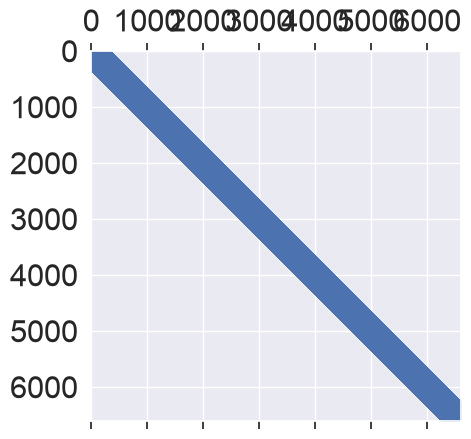

In [32]:
plt.spy(K)
plt.show()

The matrix ${\bf K}$ has a banded format, and it is also symmetric and positive definite. 

In [33]:
Kdense = K.todense()

In [34]:
Kdense.shape

(6600, 6600)

### Solving the linear system of equations using different methods:

In [35]:
F = np.zeros(K.shape[0])
F[1]=-1

#### a) la.solve

In [36]:
u1 = sla.solve(Kdense,F)
u1.shape

(6600,)

In [37]:
%timeit sla.solve(Kdense,F)

1.11 s ± 12.9 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


#### b) LU factorization

In [38]:
P,L,U = sla.lu(Kdense)
y = sla.solve_triangular(L, np.dot(P.T, F), lower=True)
u2 = sla.solve_triangular(U, y)
u2.shape

(6600,)

In [39]:
%timeit sla.lu(Kdense)
%timeit sla.solve_triangular(L, np.dot(P.T, F), lower=True)
%timeit sla.solve_triangular(U, y)

1.11 s ± 6.69 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
25.4 ms ± 3.17 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
26 ms ± 149 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


#### c) Cholesky factorization

applicable when it is a symmetric matrix and also positive definite.
$$
A = L L^T \\
\Rightarrow L \underbrace{L^T x}_{y} = b \\
\text{solve for } L y = b \text{ then } L^T x = y
$$

In [40]:
Kcho = sla.cholesky(Kdense)
u3 = sla.cho_solve((Kcho,False),F)
u3.shape

(6600,)

In [41]:
%timeit sla.cholesky(Kdense)
%timeit sla.cho_solve((Kcho,False),F)

472 ms ± 3.55 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
105 ms ± 637 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


#### d) Sparse solve

In [42]:
from scipy.sparse.linalg import spsolve

In [43]:
u4 = spsolve(K,F)
u4.shape

(6600,)

In [44]:
%timeit spsolve(K,F)

29.4 ms ± 127 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


## 5) LU Factorization

Factorize the matrix $A$ as $A = LU$:  
$$
A=
\begin{bmatrix}
a_{11} & a_{12} & \cdots & a_{1n}\\
a_{21} & a_{22} & \cdots & a_{2n}\\
\vdots & \vdots & \ddots & \vdots\\
a_{n1} & a_{n2} & \cdots & a_{nn}
\end{bmatrix}
=
\begin{bmatrix}
a_{11} & \mathbf{a_{12}^{T}}\\
\mathbf{a_{21}} & \mathbf{A_{22}}
\end{bmatrix}
=
\begin{bmatrix}
u_{11} & \mathbf{u_{12}^{T}}\\
u_{11}\mathbf{l_{21}} & \mathbf{l_{21}}\mathbf{u_{12}^{T}}+\mathbf{L_{22}}\mathbf{U_{22}}
\end{bmatrix}
=
\begin{bmatrix}
1 & 0\\
\mathbf{l_{21}} & \mathbf{L_{22}}
\end{bmatrix}
\begin{bmatrix}
u_{11} & \mathbf{u_{12}^{T}}\\
0 & \mathbf{U_{22}}
\end{bmatrix}
\\
$$

1) First row of $U$ is the first row of $A$  
2) First column of $L$ is the First column of $A$ over $u_{11}$, or $\mathbf{l_{21}} = \frac{1}{u_{11}} \mathbf{a_{21}}$  
3) $M = \mathbf{L_{22}}\mathbf{U_{22}} = \mathbf{A_{22}}-\mathbf{L_{21}}\mathbf{u_{12}^{T}}$

In [45]:
n = 4

A = np.array([[2.0,8,4,1],[1,2,3,3],[1,2,6,2],[1,3,4,2]])

## Algorithm 1
## Factorization using the block-format, 
## creating new matrices L and U
## and not modifying A
print("LU factorization using Algorithm 1")
U = np.zeros((n,n))
L = np.zeros((n,n))
M = A.copy()
for i in range(n):
    U[i,i:] = M[i,i:]
    L[i:,i] = M[i:,i]/U[i,i]
    M[i+1:,i+1:] -= np.outer(L[i+1:,i],U[i,i+1:])
print("U = ",U)
print("L = ",L)



## Algorithm 2
## Factorization using the block-format 
## Matrices L and U are stored in the input matrix
## that could be a copy of A or A itself
print("LU factorization using Algorithm 2")  
M = A.copy()
for i in range(n):
    M[i+1:,i] = M[i+1:,i]/M[i,i]
    M[i+1:,i+1:] -= np.outer(M[i+1:,i],M[i,i+1:]) 
print("M = ",M)



## Algorithm 3
## "Typical" Gaussian Elimination algorithm
print("LU factorization using Algorithm 3")
print(' "Traditional" Gaussian elimination') 
M = A.copy()
for i in range(n-1):
    for j in range(i+1,n):
        M[j,i] = M[j,i]/M[i,i]
        for k in range(i+1,n):
            M[j,k] -= M[j,i]*M[i,k]
print("M = ",M)

P, L, U = sla.lu(A)

LU factorization using Algorithm 1
U =  [[ 2.    8.    4.    1.  ]
 [ 0.   -2.    1.    2.5 ]
 [ 0.    0.    3.   -1.  ]
 [ 0.    0.    0.    0.75]]
L =  [[1.  0.  0.  0. ]
 [0.5 1.  0.  0. ]
 [0.5 1.  1.  0. ]
 [0.5 0.5 0.5 1. ]]
LU factorization using Algorithm 2
M =  [[ 2.    8.    4.    1.  ]
 [ 0.5  -2.    1.    2.5 ]
 [ 0.5   1.    3.   -1.  ]
 [ 0.5   0.5   0.5   0.75]]
LU factorization using Algorithm 3
 "Traditional" Gaussian elimination
M =  [[ 2.    8.    4.    1.  ]
 [ 0.5  -2.    1.    2.5 ]
 [ 0.5   1.    3.   -1.  ]
 [ 0.5   0.5   0.5   0.75]]


In [46]:
## Factorize and solve 
M = A.copy()
for i in range(n):
    M[i+1:,i] = M[i+1:,i]/M[i,i]
    M[i+1:,i+1:] -= np.outer(M[i+1:,i],M[i,i+1:]) 

print("Solve system of equations for ")
b = np.array([2,2,1,4])
print("b = ",b)
x = np.zeros(n)
y = np.zeros(n)

# Foward-substitution - solve Ly = b for y
for i in range(0, n):
    tmp = b[i]
    for j in range(0, i):
        tmp -= y[j]*M[i,j]
    y[i]=tmp
#print(y)

# Backward substitution - solve Ux = y for x
for i in range(n-1, -1, -1):
    tmp = y[i]
    for j in range(i+1, n):
        tmp -= x[j]*M[i,j]
    x[i] = tmp/M[i,i]
print("Solution is:")
print("x = ",x)

Solve system of equations for 
b =  [2 2 1 4]
Solution is:
x =  [-23.   5.   1.   4.]


In [47]:
la.solve(A,b)

array([-23.,   5.,   1.,   4.])

##  6) Relative cost of matrix operations

In [48]:
n_values = (10**np.linspace(1, 4, 15)).astype(np.int32)
n_values

array([   10,    16,    26,    43,    71,   117,   193,   316,   517,
         848,  1389,  2275,  3727,  6105, 10000], dtype=int32)

In [49]:
times_matmul = []
times_lu = []
times_chol = []

for n in n_values:
    print(n)
    A = np.random.randn(n, n)
    A = A.T@A
    start_time = time()
    A.dot(A)
    times_matmul.append(time() - start_time)
    start_time = time()
    sla.lu(A)
    times_lu.append(time() - start_time)
    start_time = time()
    sla.cholesky(A)
    times_chol.append(time() - start_time)

10
16
26
43
71
117
193
316
517
848
1389
2275
3727
6105
10000


Text(0, 0.5, 'Wall time [s]')

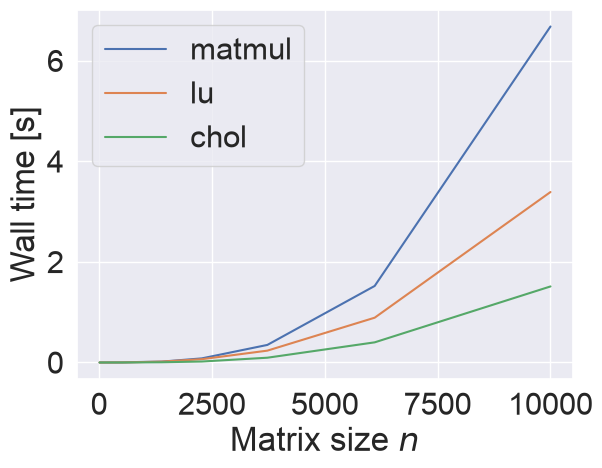

In [50]:
plt.plot(n_values, times_matmul, label='matmul')
plt.plot(n_values, times_lu, label='lu')
plt.plot(n_values, times_chol, label='chol')
plt.legend(loc="best")
plt.xlabel("Matrix size $n$")
plt.ylabel("Wall time [s]")

* The faster algorithms make the slower ones look bad. But... it's all relative.
* Can we get a better plot?
* Can we see the asymptotic cost ($O(n^3)$) of these algorithms from the plot?

Text(0, 0.5, 'Wall time [s]')

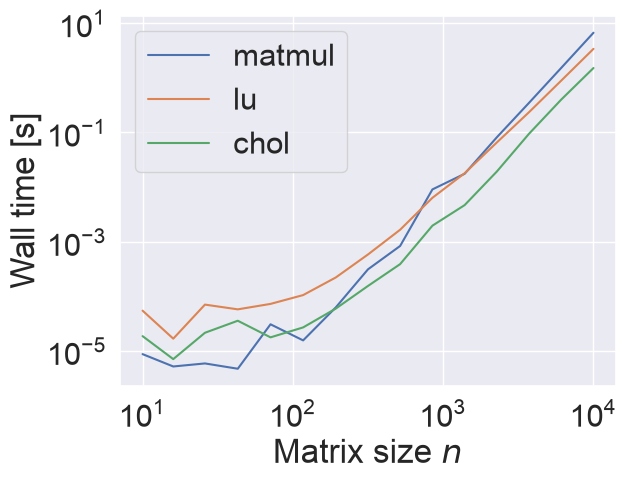

In [51]:
plt.loglog(n_values, times_matmul, label='matmul')
plt.loglog(n_values, times_lu, label='lu')
plt.loglog(n_values, times_chol, label='chol')
plt.legend(loc="best")
plt.xlabel("Matrix size $n$")
plt.ylabel("Wall time [s]")

Computation complexity of LU factorization is $O(\frac{2}{3} n^3)$  
Computation complexity of Cholesky factorization is $O(\frac{1}{3} n^3)$  
Computation complexity of Matrix-matrix multiplication is $O(2n^3)$

Computation complexity of LU solve is $O(n^2)$

## 7) Simple example


$$
Ax = \begin{bmatrix}c&1\\-1&1\end{bmatrix}\begin{bmatrix}x_1\\x_2\end{bmatrix}
=
\begin{bmatrix}b_1\\b_2\end{bmatrix}
$$
with an exact solution of
$$
x_{exact} = \begin{bmatrix}1\\1\end{bmatrix}
$$

In [52]:
def myLU(A): 
    M = A.copy()
    for i in range(A.shape[0]):
        M[i+1:,i] = M[i+1:,i]/M[i,i]
        M[i+1:,i+1:] -= np.outer(M[i+1:,i],M[i,i+1:]) 
    return M

In [53]:
# Creating the arrays
c = 1e-16
A = np.array([[c, 1.], [-1, 1]])
# xx is the exact solution
xx = np.array([1,1])
b = A.dot(xx)

# Comput the LU
M = myLU(A)
L = np.tril(M,-1) + np.eye(2,2)
U = np.triu(M)

# Solve
# x is the numerical (xhat)
y = sla.solve_triangular(L, b, lower=True)
x = sla.solve_triangular(U, y)


print("Exact solution = ", xx)

print("Computed solution = ",x)

print("Error = ", la.norm(xx-x))


Exact solution =  [1 1]
Computed solution =  [0. 1.]
Error =  1.0


Is the matrix A singular?

A) YES

B) NO


In [54]:
la.inv(A)

array([[ 1.e+00, -1.e+00],
       [ 1.e+00,  1.e-16]])

A is not singular, LU might not be appropriate.

## 8) LU with Pivoting

In [55]:
# Creating the arrays
c = 1e-16
A = np.array([[c, 1.], [-1, 1]])
# xx is the exact solution
xx = np.array([1,1])
b = A.dot(xx)

x = la.solve(A,b)

## or 

P,L,U = sla.lu(A)
y = sla.solve_triangular(L, P.T@b, lower=True)
x = sla.solve_triangular(U, y)


print("Exact solution = ", xx)

print("Computed solution = ",x)

print("Error = ", la.norm(xx-x))

Exact solution =  [1 1]
Computed solution =  [1. 1.]
Error =  0.0


In [56]:
P

array([[0., 1.],
       [1., 0.]])